In [1]:
%pip install pandas

Defaulting to user installation because normal site-packages is not writeableNote: you may need to restart the kernel to use updated packages.



In [2]:
import pandas as pd

print("Pandas version:", pd.__version__)

Pandas version: 2.2.2


In [3]:
%pip install numpy pandas matplotlib seaborn scikit-learn

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.


In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn

print("All libraries are working!")

All libraries are working!


In [5]:
import re

def scan_sensitive_data(text):
    patterns = {
        "Email": r"\b[A-Za-z0-9._%+-]+@[A-Za-z0-9.-]+\.[A-Za-z]{2,}\b",
        "Phone Number": r"(?<!\d)(?:\+91[- ]?)?[6-9]\d{9}(?!\d)",
        "Possible API Key": r"\b(?:api[_-]?key|secret[_-]?key)\s*[:=]\s*['\"]?[\w-]{8,}"
    }

    findings = {}

    for label, pattern in patterns.items():
        findings[label] = re.findall(
            pattern, text, flags=re.IGNORECASE
        )

    return findings


sample_text = """
Contact: demo@example.com
Phone: 9876543210
api_key = DEMO123456789
"""

results = scan_sensitive_data(sample_text)

for category, matches in results.items():
    if matches:
        print(f"WARNING: {category} detected ({len(matches)})")
    else:
        print(f"SAFE: No {category} detected")

In [6]:
def calculate_risk(results):
    risk_score = 0

    if results["Email"]:
        risk_score += 20

    if results["Phone Number"]:
        risk_score += 30

    if results["Possible API Key"]:
        risk_score += 50

    if risk_score >= 70:
        risk_level = "HIGH"
    elif risk_score >= 30:
        risk_level = "MEDIUM"
    else:
        risk_level = "LOW"

    return risk_score, risk_level


score, level = calculate_risk(results)

print("VaultVision Security Report")
print("----------------------------")
print("Risk Score:", score, "/ 100")
print("Risk Level:", level)

VaultVision Security Report
----------------------------
Risk Score: 100 / 100
Risk Level: HIGH


In [7]:
def security_gateway(text):
    findings = scan_sensitive_data(text)
    score, level = calculate_risk(findings)

    print("Risk Score:", score)
    print("Risk Level:", level)

    if level == "HIGH":
        print("STATUS: BLOCKED")
        print("Reason: High-risk sensitive data detected.")
    elif level == "MEDIUM":
        print("STATUS: REVIEW REQUIRED")
    else:
        print("STATUS: ALLOWED")

    return findings


security_gateway(sample_text)

Risk Score: 100
Risk Level: HIGH
STATUS: BLOCKED
Reason: High-risk sensitive data detected.


{'Email': ['demo@example.com'],
 'Phone Number': ['9876543210'],
 'Possible API Key': ['api_key = DEMO123456789']}

===== VAULTVISION SECURITY DASHBOARD =====
Total Scans: 1
Sensitive Data Findings: 3
Blocked Requests: 1
Risk Score: 100 / 100


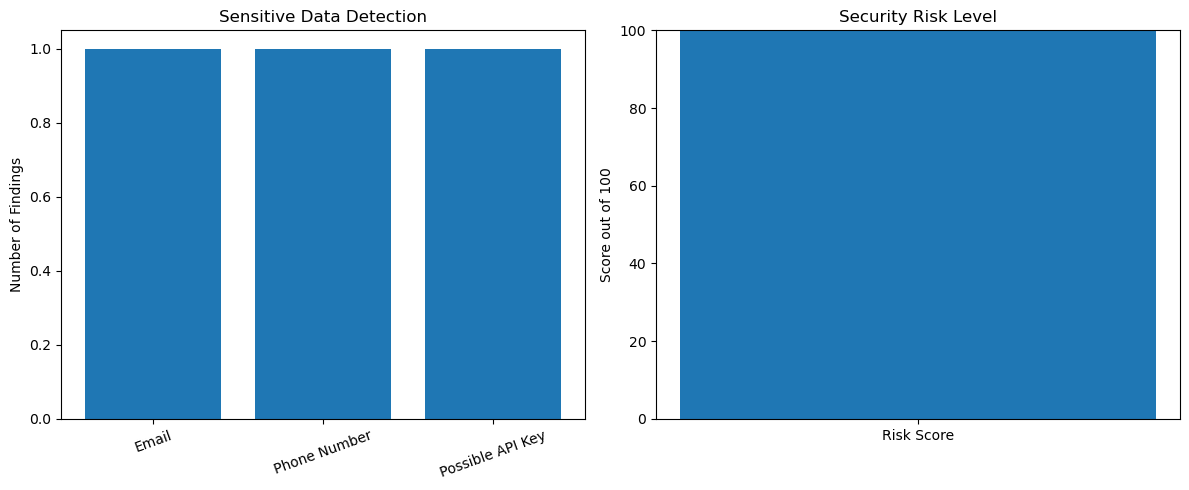

In [8]:
import matplotlib.pyplot as plt

# Security dashboard data
total_scans = 1
detected_leaks = sum(
    len(matches) for matches in results.values()
)
blocked_requests = 1
risk_score = score

# Display report
print("===== VAULTVISION SECURITY DASHBOARD =====")
print("Total Scans:", total_scans)
print("Sensitive Data Findings:", detected_leaks)
print("Blocked Requests:", blocked_requests)
print("Risk Score:", risk_score, "/ 100")

# Create dashboard charts
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Chart 1: Findings by category
categories = list(results.keys())
counts = [len(results[c]) for c in categories]

axes[0].bar(categories, counts)
axes[0].set_title("Sensitive Data Detection")
axes[0].set_ylabel("Number of Findings")
axes[0].tick_params(axis="x", rotation=20)

# Chart 2: Risk score
axes[1].bar(["Risk Score"], [risk_score])
axes[1].set_title("Security Risk Level")
axes[1].set_ylabel("Score out of 100")
axes[1].set_ylim(0, 100)

plt.tight_layout()
plt.show()

In [9]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline

# 1. Sample training dataset
texts = [
    "Hello, how are you?",
    "The meeting is scheduled for tomorrow",
    "Python is a programming language",
    "Please find the attached project report",
    "My email is rahul@example.com",
    "My phone number is 9876543210",
    "My password is Secret123",
    "api_key = ABCDEFGHIJK12345",
    "Send customer personal information",
    "My credit card number is 1234567890123456",
    "Let's discuss the project today",
    "The weather is nice today",
    "Please share the confidential customer records",
    "My secret_key is XYZ123456789"
]

labels = [
    "Safe", "Safe", "Safe", "Safe",
    "Sensitive", "Sensitive", "Sensitive",
    "Sensitive", "Sensitive", "Sensitive",
    "Safe", "Safe", "Sensitive", "Sensitive"
]

# 2. Create the AI pipeline
model = Pipeline([
    ("tfidf", TfidfVectorizer()),
    ("classifier", LogisticRegression(max_iter=1000))
])

# 3. Train the model
model.fit(texts, labels)

print("VaultVision AI model trained successfully!")

VaultVision AI model trained successfully!


In [10]:
def ai_detect(text):
    prediction = model.predict([text])[0]
    print("Input:", text)
    print("AI Prediction:", prediction)

    if prediction == "Sensitive":
        print("STATUS: REVIEW / BLOCK")
    else:
        print("STATUS: ALLOW")

    print("-" * 40)


ai_detect("My password is Rahul123")
ai_detect("Let's study Python today")
ai_detect("Confidential customer information")

Input: My password is Rahul123
AI Prediction: Sensitive
STATUS: REVIEW / BLOCK
----------------------------------------
Input: Let's study Python today
AI Prediction: Safe
STATUS: ALLOW
----------------------------------------
Input: Confidential customer information
AI Prediction: Sensitive
STATUS: REVIEW / BLOCK
----------------------------------------


In [11]:
def vaultvision_scan(text):
    print("=" * 45)
    print("       VAULTVISION SECURITY SCANNER")
    print("=" * 45)

    # 1. Pattern-based detection
    findings = scan_sensitive_data(text)

    # 2. AI prediction
    ai_prediction = model.predict([text])[0]

    # 3. Calculate risk score
    score, level = calculate_risk(findings)

    # 4. Adjust risk if AI flags sensitive text
    if ai_prediction == "Sensitive" and score < 30:
        score = 30
        level = "MEDIUM"

    # 5. Display security report
    print("AI Prediction:", ai_prediction)
    print("Risk Score:", score, "/ 100")
    print("Risk Level:", level)

    for category, matches in findings.items():
        if matches:
            print(f"{category}: {len(matches)} detected")

    # 6. Gateway decision
    if level == "HIGH":
        print("STATUS: BLOCKED")
    elif level == "MEDIUM":
        print("STATUS: REVIEW REQUIRED")
    else:
        print("STATUS: ALLOWED")

    print("=" * 45)

    return {
        "ai_prediction": ai_prediction,
        "risk_score": score,
        "risk_level": level,
        "findings": findings
    }


# Test the scanner
report = vaultvision_scan(
    "My email is demo@example.com and password is Secret123"
)

       VAULTVISION SECURITY SCANNER
AI Prediction: Sensitive
Risk Score: 30 / 100
Risk Level: MEDIUM
Email: 1 detected
STATUS: REVIEW REQUIRED


In [12]:
vaultvision_scan("Let's learn Python today")

vaultvision_scan("My phone number is 9876543210")

vaultvision_scan("api_key = DEMO123456789")

       VAULTVISION SECURITY SCANNER
AI Prediction: Safe
Risk Score: 0 / 100
Risk Level: LOW
STATUS: ALLOWED
       VAULTVISION SECURITY SCANNER
AI Prediction: Sensitive
Risk Score: 30 / 100
Risk Level: MEDIUM
Phone Number: 1 detected
STATUS: REVIEW REQUIRED
       VAULTVISION SECURITY SCANNER
AI Prediction: Sensitive
Risk Score: 50 / 100
Risk Level: MEDIUM
Possible API Key: 1 detected
STATUS: REVIEW REQUIRED


{'ai_prediction': 'Sensitive',
 'risk_score': 50,
 'risk_level': 'MEDIUM',
 'findings': {'Email': [],
  'Phone Number': [],
  'Possible API Key': ['api_key = DEMO123456789']}}

       VAULTVISION SECURITY SCANNER
AI Prediction: Safe
Risk Score: 0 / 100
Risk Level: LOW
STATUS: ALLOWED
       VAULTVISION SECURITY SCANNER
AI Prediction: Sensitive
Risk Score: 30 / 100
Risk Level: MEDIUM
Email: 1 detected
STATUS: REVIEW REQUIRED
       VAULTVISION SECURITY SCANNER
AI Prediction: Sensitive
Risk Score: 50 / 100
Risk Level: MEDIUM
Possible API Key: 1 detected
STATUS: REVIEW REQUIRED


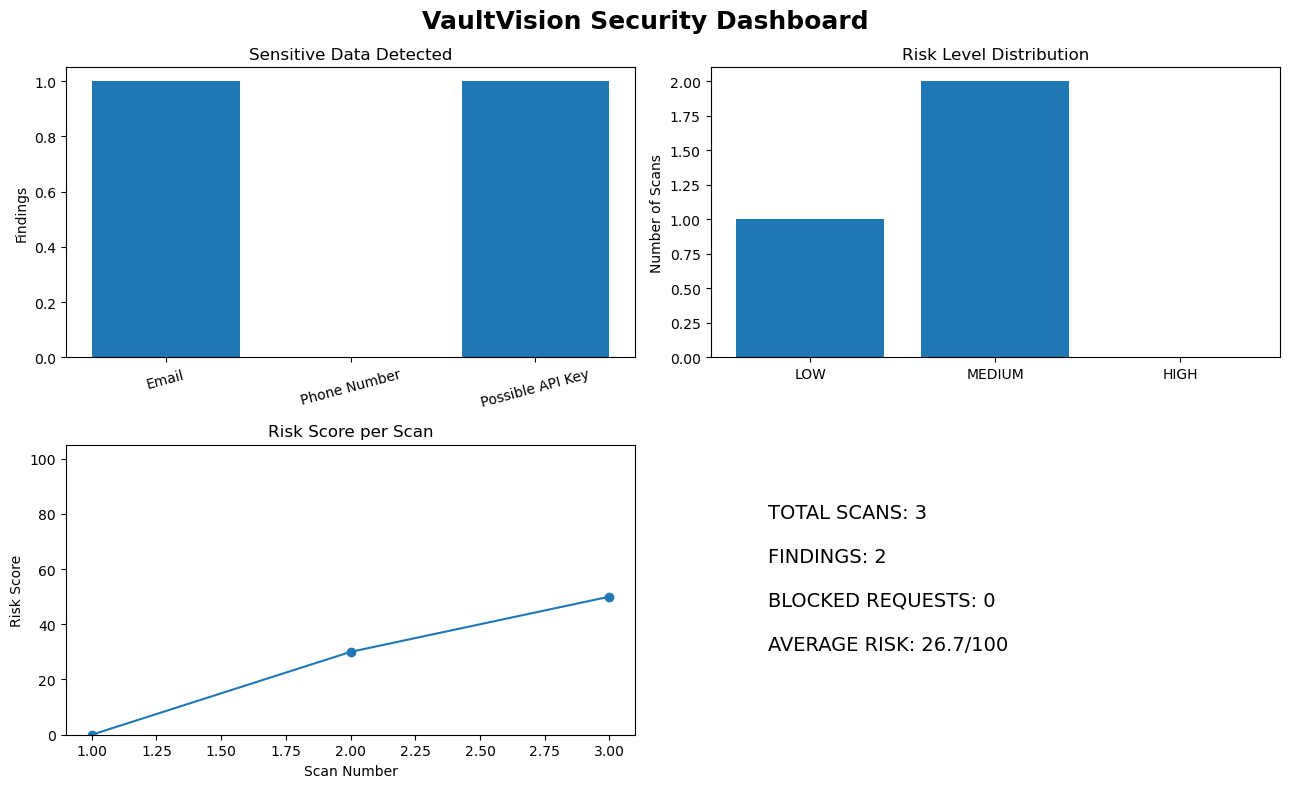

In [13]:
import matplotlib.pyplot as plt

# Store scan history
scan_history = []

# Run scan and save report
def run_and_log_scan(text):
    report = vaultvision_scan(text)
    scan_history.append(report)
    return report

# Demo scans
run_and_log_scan("Let's learn Python today")
run_and_log_scan("Contact: demo@example.com")
run_and_log_scan("api_key = DEMO123456789")

# Calculate dashboard metrics
total_scans = len(scan_history)

total_findings = sum(
    len(matches)
    for report in scan_history
    for matches in report["findings"].values()
)

blocked = sum(
    report["risk_level"] == "HIGH"
    for report in scan_history
)

# Count findings by category
categories = ["Email", "Phone Number", "Possible API Key"]

counts = [
    sum(
        len(report["findings"][category])
        for report in scan_history
    )
    for category in categories
]

# Count risk levels
risk_levels = ["LOW", "MEDIUM", "HIGH"]

risk_counts = [
    sum(report["risk_level"] == level
        for report in scan_history)
    for level in risk_levels
]

# Create dashboard
fig, axes = plt.subplots(2, 2, figsize=(13, 8))
fig.suptitle("VaultVision Security Dashboard",
             fontsize=18, fontweight="bold")

# Graph 1: Detection by category
axes[0, 0].bar(categories, counts)
axes[0, 0].set_title("Sensitive Data Detected")
axes[0, 0].set_ylabel("Findings")
axes[0, 0].tick_params(axis="x", rotation=15)

# Graph 2: Risk distribution
axes[0, 1].bar(risk_levels, risk_counts)
axes[0, 1].set_title("Risk Level Distribution")
axes[0, 1].set_ylabel("Number of Scans")

# Graph 3: Risk score per scan
scores = [r["risk_score"] for r in scan_history]
axes[1, 0].plot(
    range(1, total_scans + 1),
    scores,
    marker="o"
)
axes[1, 0].set_title("Risk Score per Scan")
axes[1, 0].set_xlabel("Scan Number")
axes[1, 0].set_ylabel("Risk Score")
axes[1, 0].set_ylim(0, 105)

# Graph 4: Summary
axes[1, 1].axis("off")
summary = (
    f"TOTAL SCANS: {total_scans}\n\n"
    f"FINDINGS: {total_findings}\n\n"
    f"BLOCKED REQUESTS: {blocked}\n\n"
    f"AVERAGE RISK: {sum(scores) / total_scans:.1f}/100"
    if total_scans else "No scans yet"
)
axes[1, 1].text(
    0.1, 0.8, summary,
    fontsize=14,
    va="top"
)

plt.tight_layout()
plt.show()

In [14]:
import ipywidgets as widgets
from IPython.display import display, clear_output

text_input = widgets.Textarea(
    placeholder="Enter text to scan for sensitive data...",
    description="Input:",
    layout=widgets.Layout(width="80%", height="120px")
)

scan_button = widgets.Button(
    description="Scan for Leaks",
    button_style="danger",
    icon="search"
)

output = widgets.Output()

def on_scan_click(button):
    with output:
        clear_output()

        text = text_input.value.strip()

        if not text:
            print("Please enter some text to scan.")
            return

        report = vaultvision_scan(text)

scan_button.on_click(on_scan_click)

display(text_input, scan_button, output)

Textarea(value='', description='Input:', layout=Layout(height='120px', width='80%'), placeholder='Enter text t…

Button(button_style='danger', description='Scan for Leaks', icon='search', style=ButtonStyle())

Output()

In [15]:
%pip install ipywidgets

Defaulting to user installation because normal site-packages is not writeable
  Using cached isoduration-20.11.0-py3-none-any.whl.metadata (5.7 kB)
  Using cached uri_template-1.3.0-py3-none-any.whl.metadata (8.8 kB)
  Using cached webcolors-25.10.0-py3-none-any.whl.metadata (2.2 kB)
Using cached webcolors-25.10.0-py3-none-any.whl (14 kB)
Using cached isoduration-20.11.0-py3-none-any.whl (11 kB)
Using cached uri_template-1.3.0-py3-none-any.whl (11 kB)
Note: you may need to restart the kernel to use updated packages.


In [16]:
%pip install streamlit pandas matplotlib

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.


In [19]:
%pip install streamlit pandas matplotlib

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.


In [20]:
%%writefile app.py
import re
import streamlit as st
import pandas as pd

st.set_page_config(
    page_title="VaultVision",
    page_icon="🛡️",
    layout="wide"
)

st.markdown("""
<style>
.stApp {
    background-color: #07111F;
    color: #E5EEFF;
}
[data-testid="stMetric"] {
    background: #111E30;
    border: 1px solid #263B54;
    padding: 18px;
    border-radius: 12px;
}
h1, h2, h3 {
    color: #39E6C2;
}
</style>
""", unsafe_allow_html=True)

st.title("🛡️ VaultVision")
st.caption("AI-Powered Privacy-Aware Data Leakage Prevention Gateway")

st.sidebar.title("VaultVision")
page = st.sidebar.radio(
    "Navigation",
    ["Dashboard", "Scan & Analyze", "Scan History", "About"]
)

if "history" not in st.session_state:
    st.session_state.history = []

def scan_text(text):
    patterns = {
        "Email": r"\b[\w.+-]+@[\w.-]+\.[A-Za-z]{2,}\b",
        "Phone Number": r"(?<!\d)(?:\+91[- ]?)?[6-9]\d{9}(?!\d)",
        "Possible API Key": r"\b(?:api[_-]?key|secret[_-]?key)\s*[:=]\s*['\"]?[\w-]{8,}"
    }

    findings = {
        name: re.findall(pattern, text, re.I)
        for name, pattern in patterns.items()
    }

    score = min(
        100,
        20 * len(findings["Email"])
        + 30 * len(findings["Phone Number"])
        + 50 * len(findings["Possible API Key"])
    )

    risk = (
        "HIGH" if score >= 70
        else "MEDIUM" if score >= 30
        else "LOW"
    )

    return findings, score, risk

if page == "Dashboard":
    st.subheader("Security Overview")

    history = st.session_state.history

    total = len(history)
    leaks = sum(
        sum(len(v) for v in item["findings"].values())
        for item in history
    )
    blocked = sum(item["risk"] == "HIGH" for item in history)
    high_risk = blocked

    a, b, c, d = st.columns(4)
    a.metric("Total Scans", total)
    b.metric("Sensitive Findings", leaks)
    c.metric("Blocked (Demo)", blocked)
    d.metric("High-Risk Scans", high_risk)

    st.subheader("Sensitive Data Detection")

    categories = ["Email", "Phone Number", "Possible API Key"]
    counts = [
        sum(len(item["findings"][cat]) for item in history)
        for cat in categories
    ]

    chart_data = pd.DataFrame({
        "Category": categories,
        "Findings": counts
    }).set_index("Category")

    st.bar_chart(chart_data)

    st.subheader("Risk Level Distribution")

    risk_counts = {
        level: sum(item["risk"] == level for item in history)
        for level in ["LOW", "MEDIUM", "HIGH"]
    }

    st.bar_chart(pd.DataFrame({
        "Scans": risk_counts
    }))

    st.info(
        "Charts show scans performed in this session. "
        "No real network traffic is being monitored."
    )

elif page == "Scan & Analyze":
    st.subheader("Scan Your Text")

    text = st.text_area(
        "Enter sample text",
        placeholder="Paste text to check for sensitive data..."
    )

    if st.button("🔍 Scan Now", type="primary"):
        if not text.strip():
            st.warning("Please enter some text.")
        else:
            findings, score, risk = scan_text(text)

            st.session_state.history.append({
                "findings": findings,
                "score": score,
                "risk": risk
            })

            x, y, z = st.columns(3)
            x.metric("Risk Score", f"{score}/100")
            y.metric("Risk Level", risk)
            z.metric(
                "Findings",
                sum(len(v) for v in findings.values())
            )

            for category, matches in findings.items():
                if matches:
                    st.warning(
                        f"{category}: {len(matches)} detected"
                    )

            if risk == "HIGH":
                st.error("BLOCKED — simulated security decision")
            elif risk == "MEDIUM":
                st.warning("REVIEW REQUIRED")
            else:
                st.success("LOW RISK — no matching patterns found")

            st.caption(
                "Demo only: low risk does not guarantee that text is safe."
            )

elif page == "Scan History":
    st.subheader("Scan History")

    if st.session_state.history:
        df = pd.DataFrame([
            {
                "Scan": i + 1,
                "Risk Score": item["score"],
                "Risk Level": item["risk"]
            }
            for i, item in enumerate(st.session_state.history)
        ])
        st.dataframe(df, use_container_width=True)
    else:
        st.info("No scans yet. Open Scan & Analyze to begin.")

elif page == "About":
    st.subheader("About VaultVision")
    st.write(
        "VaultVision demonstrates privacy-aware data leakage "
        "detection using pattern matching, risk scoring, "
        "and visual security analytics."
    )
    st.warning(
        "This prototype scans entered text only. "
        "It does not inspect actual network traffic or upload requests."
    )

Overwriting app.py


In [21]:
!streamlit run app.py

'streamlit' is not recognized as an internal or external command,
operable program or batch file.


In [22]:
%pip install streamlit

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.


In [23]:
!python -m streamlit run app.py

C:\Users\hp\AppData\Local\Programs\Python\Python314\python.exe: No module named streamlit


In [24]:
import sys
!{sys.executable} -m pip install streamlit

Defaulting to user installation because normal site-packages is not writeable


In [25]:
import sys
!{sys.executable} -m streamlit --version

Streamlit, version 1.32.0


In [1]:
import sys
!{sys.executable} -m pip show streamlit

Name: streamlit
Version: 1.32.0
Summary: A faster way to build and share data apps
Home-page: https://streamlit.io
Author: Snowflake Inc
Author-email: hello@streamlit.io
License: Apache License 2.0
Location: C:\ProgramData\anaconda3\Lib\site-packages
Requires: altair, blinker, cachetools, click, gitpython, numpy, packaging, pandas, pillow, protobuf, pyarrow, pydeck, requests, rich, tenacity, toml, tornado, typing-extensions, watchdog
Required-by: 


In [ ]:
import sys
!{sys.executable} -m streamlit run app.py